In [1]:
import pandas as pd
data={
"Message":[
"Congratulations you won a free prize",
"Please attend the meeting at 5 PM",
"Claim your free reward now",
"Please send the project report today",
"You have been selected for a cash reward",
"Can we discuss the assignment tomorrow",
"Click here to win a free gift",
"Your interview is scheduled for Monday",
"Exclusive offer claim your free coupon",
"Please call me when you are available",
"You won a lottery prize claim now",
"Team meeting starts at 10 AM",
"Get your free mobile recharge today",
"Please submit the document before evening",
"Congratulations you are the lucky winner",
"Can you share the notes with me",
"Claim your bonus reward immediately",
"The project presentation is tomorrow",
"Win a free vacation by clicking this link",
"Please check the email I sent",
"You have won a special cash prize",
"Let's meet after the class",
"Limited offer get your free gift now",
"Please send me the meeting details",
"Congratulations claim your reward today",
"The report has been completed",
"Free prize waiting for you click now",
"Can you review my project once",
"Urgent claim your free voucher",
"Please bring the documents tomorrow",
"You are selected to receive a free reward",
"The class will start at nine",
"Win cash now by claiming this offer",
"Please share the presentation file",
"Get an exclusive free bonus today",
"Are you coming to the meeting",
"Congratulations you won a free coupon",
"Please complete the assignment today",
"Claim your lottery reward immediately",
"Let's discuss the project after lunch"
],
"Label":[
"Spam","Not Spam","Spam","Not Spam","Spam","Not Spam","Spam","Not Spam","Spam","Not Spam",
"Spam","Not Spam","Spam","Not Spam","Spam","Not Spam","Spam","Not Spam","Spam","Not Spam",
"Spam","Not Spam","Spam","Not Spam","Spam","Not Spam","Spam","Not Spam","Spam","Not Spam",
"Spam","Not Spam","Spam","Not Spam","Spam","Not Spam","Spam","Not Spam","Spam","Not Spam"
]}
df=pd.DataFrame(data)
df.to_csv("spam_dataset.csv",index=False)
print("Dataset saved successfully.")
print("Shape:",df.shape)
print(df.head())
print("\nClass Distribution:")
print(df["Label"].value_counts())

Dataset saved successfully.
Shape: (40, 2)
                                    Message     Label
0      Congratulations you won a free prize      Spam
1         Please attend the meeting at 5 PM  Not Spam
2                Claim your free reward now      Spam
3      Please send the project report today  Not Spam
4  You have been selected for a cash reward      Spam

Class Distribution:
Label
Spam        20
Not Spam    20
Name: count, dtype: int64


In [2]:
import pandas as pd
df=pd.read_csv("spam_dataset.csv")
print(df.head())
print("Shape:",df.shape)
print("Missing Values:")
print(df.isnull().sum())

                                    Message     Label
0      Congratulations you won a free prize      Spam
1         Please attend the meeting at 5 PM  Not Spam
2                Claim your free reward now      Spam
3      Please send the project report today  Not Spam
4  You have been selected for a cash reward      Spam
Shape: (40, 2)
Missing Values:
Message    0
Label      0
dtype: int64


In [3]:
import re
def clean_text(text):
    text=text.lower()
    text=re.sub(r"[^a-zA-Z\s]","",text)
    tokens=text.split()
    return " ".join(tokens)
df["Cleaned_Message"]=df["Message"].apply(clean_text)
print(df[["Message","Cleaned_Message"]].head())

                                    Message  \
0      Congratulations you won a free prize   
1         Please attend the meeting at 5 PM   
2                Claim your free reward now   
3      Please send the project report today   
4  You have been selected for a cash reward   

                            Cleaned_Message  
0      congratulations you won a free prize  
1           please attend the meeting at pm  
2                claim your free reward now  
3      please send the project report today  
4  you have been selected for a cash reward  


In [6]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(df["Cleaned_Message"],df["Label"],test_size=0.25,random_state=42,stratify=df["Label"])
print("Training Samples:",len(X_train))
print("Testing Samples:",len(X_test))

Training Samples: 30
Testing Samples: 10


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer=TfidfVectorizer(stop_words="english",ngram_range=(1,2))
X_train_tfidf=vectorizer.fit_transform(X_train)
X_test_tfidf=vectorizer.transform(X_test)
print("TF-IDF Training Shape:",X_train_tfidf.shape)
print("TF-IDF Testing Shape:",X_test_tfidf.shape)
print("Number of Features:",len(vectorizer.get_feature_names_out()))

TF-IDF Training Shape: (30, 128)
TF-IDF Testing Shape: (10, 128)
Number of Features: 128


In [8]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf,y_train)
print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [9]:
y_pred=model.predict(X_test_tfidf)
print("Actual Labels:")
print(y_test.to_numpy())
print("Predicted Labels:")
print(y_pred)

Actual Labels:
['Not Spam' 'Not Spam' 'Spam' 'Not Spam' 'Spam' 'Not Spam' 'Spam' 'Spam'
 'Spam' 'Not Spam']
Predicted Labels:
['Not Spam' 'Not Spam' 'Spam' 'Not Spam' 'Spam' 'Not Spam' 'Spam' 'Spam'
 'Spam' 'Not Spam']


In [10]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
accuracy=accuracy_score(y_test,y_pred)
precision=precision_score(y_test,y_pred,pos_label="Spam")
recall=recall_score(y_test,y_pred,pos_label="Spam")
f1=f1_score(y_test,y_pred,pos_label="Spam")
print("Accuracy:",round(accuracy,4))
print("Precision:",round(precision,4))
print("Recall:",round(recall,4))
print("F1 Score:",round(f1,4))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


Confusion Matrix:
[[5 0]
 [0 5]]


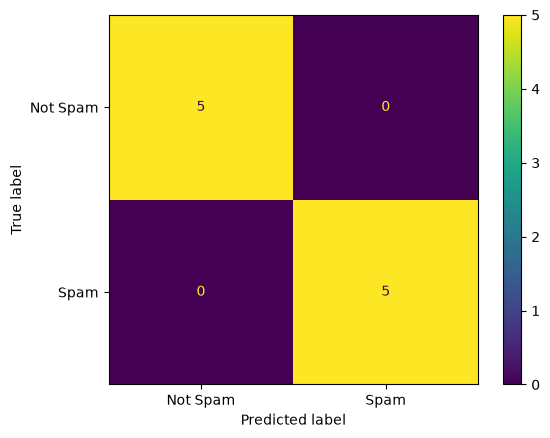

In [11]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
cm=confusion_matrix(y_test,y_pred,labels=["Not Spam","Spam"])
print("Confusion Matrix:")
print(cm)
ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Not Spam","Spam"]).plot()

In [12]:
new_messages=[
"Congratulations you won a free reward",
"Please send the project file",
"Claim your free cash prize now",
"Can we meet after class tomorrow"
]
new_cleaned=[clean_text(message) for message in new_messages]
new_tfidf=vectorizer.transform(new_cleaned)
predictions=model.predict(new_tfidf)
probabilities=model.predict_proba(new_tfidf)
for i in range(len(new_messages)):
    print("Message:",new_messages[i])
    print("Prediction:",predictions[i])
    print("Confidence:",round(float(max(probabilities[i]))*100,2),"%")
    print()

Message: Congratulations you won a free reward
Prediction: Spam
Confidence: 67.23 %

Message: Please send the project file
Prediction: Not Spam
Confidence: 64.61 %

Message: Claim your free cash prize now
Prediction: Spam
Confidence: 69.08 %

Message: Can we meet after class tomorrow
Prediction: Not Spam
Confidence: 60.98 %



In [13]:
import numpy as np
features=vectorizer.get_feature_names_out()
coefficients=model.coef_[0]
top_indices=np.argsort(coefficients)[-10:][::-1]
print("Important Spam Words:")
for index in top_indices:
    print(features[index],round(coefficients[index],3))

Important Spam Words:
free 0.697
claim 0.517
reward 0.479
congratulations 0.396
cash 0.393
prize 0.366
won 0.363
win 0.353
selected 0.293
click 0.268


In [14]:
import joblib
joblib.dump(model,"spam_classifier.pkl")
joblib.dump(vectorizer,"tfidf_vectorizer.pkl")
print("Model saved as spam_classifier.pkl")
print("TF-IDF vectorizer saved as tfidf_vectorizer.pkl")

Model saved as spam_classifier.pkl
TF-IDF vectorizer saved as tfidf_vectorizer.pkl


In [15]:
loaded_model=joblib.load("spam_classifier.pkl")
loaded_vectorizer=joblib.load("tfidf_vectorizer.pkl")
message="You have won a free prize"
cleaned=clean_text(message)
vector=loaded_vectorizer.transform([cleaned])
prediction=loaded_model.predict(vector)[0]
print("Message:",message)
print("Prediction:",prediction)

Message: You have won a free prize
Prediction: Spam


In [16]:
print("FINAL MODEL RESULTS")
print("Model: Logistic Regression")
print("Feature Extraction: TF-IDF")
print("Accuracy:",round(accuracy,4))
print("Precision:",round(precision,4))
print("Recall:",round(recall,4))
print("F1 Score:",round(f1,4))
print("Model Saved: spam_classifier.pkl")
print("Vectorizer Saved: tfidf_vectorizer.pkl")

FINAL MODEL RESULTS
Model: Logistic Regression
Feature Extraction: TF-IDF
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
Model Saved: spam_classifier.pkl
Vectorizer Saved: tfidf_vectorizer.pkl
